# Federated DenseNet-Attention for TB Screening pipeline

**How to run on Kaggle:** switch the accelerator to **GPU**, turn **Internet ON**, then **Run All**. Missing datasets are added automatically with `kagglehub` (Sec. 2b); you can also attach them by hand with *Add Input*. Paths are found automatically.

What this version fixes compared with the old notebook:

1. **Correct labels** – Shenzhen labels are read from the file name (`_0` normal, `_1` TB); NIH images are used only if their label is `No Finding`.
2. **Clean, leak-free splits** – every source is split 70/10/20 (train/val/test, stratified) *after* cleaning; the test set is never used for training, model selection or threshold tuning. Exact (MD5) duplicates and near duplicates (thumbnail correlation) between train and val/test are removed.
3. **No class-dependent filtering** – the old blur filter removed 37 % of Tawsifur TB images and no normal images, so it is off by default (blur scores are still plotted and reported).
4. **Real federated training** – each client trains a copy of the global model, FedAvg (sample-weighted) aggregates, the best round is chosen on validation loss.
5. **Real ablation** – the DenseNet121-only baseline is actually trained under the same schedule; 3 seeds; McNemar test and paired bootstrap CIs instead of hand-typed numbers.
6. **Real curves and metrics** – per-round train/val loss is logged (Fig. 4), ECE is the standard weighted ECE, latency is measured with CUDA synchronisation.
7. **Quantified explainability** – Grad-CAM energy statistics, saliency stability as a correlation over 50 images, LIME with the correct input normalisation.

Everything the paper needs is written to `/kaggle/working/tb_fl_outputs/` (CSV/JSON tables + 300-dpi figures).

## 1. Configuration

In [1]:
# ======================= CONFIG =======================
INPUT_ROOT       = "/kaggle/input"
AUTO_ADD_DATASETS = True        # download missing datasets with kagglehub (Internet must be ON)
OUT_DIR          = "/kaggle/working/tb_fl_outputs"

CLIENT_C_SOURCE  = "tawsifur"   # "tawsifur" = normal-only client from the Tawsifur Normal folder (as the paper says)
                                # "nih"      = normal-only client from NIH ChestX-ray14 'No Finding' images
CLIENT_C_SIZE    = 1000

BLUR_THRESHOLD   = 0            # variance-of-Laplacian filter. 0 = OFF (default, see note in Sec. 4).
                                # 15 reproduces the old filter, which removed 262 Tawsifur TB and 0 normal images
BLUR_RES         = 512          # blur is measured after resizing to BLUR_RES x BLUR_RES (None = native size)
NEAR_DUP_CORR    = 0.985        # val/test image is a near duplicate if its Pearson correlation (64x64 thumbnail)
                                # with any training image is >= this value (resized/re-encoded copies score > 0.99)

SPLIT            = (0.70, 0.10, 0.20)   # train / val / test fractions per source (stratified)
DATA_SEED        = 42           # fixed: every model sees the SAME split (needed for paired tests)
SEEDS            = [0, 1, 2]    # training seeds

NUM_ROUNDS       = 15
LOCAL_EPOCHS     = 2
BATCH_SIZE       = 32
LR               = 1e-4
WEIGHTED_FEDAVG  = True         # McMahan et al. (2017): weight each client by its number of samples
RUN_CENTRALISED  = True         # pooled-data upper bound with the same compute budget
USE_AMP          = True         # mixed precision on GPU (faster on T4/P100)
PRETRAINED       = True         # ImageNet weights for DenseNet121
N_BOOT           = 2000         # bootstrap resamples for confidence intervals
LOAD_WORKERS     = 8            # threads for image decoding
RESUME           = True         # skip runs whose results are already saved in OUT_DIR
IMG = 224

## 2. Imports, environment, seeding

In [2]:
import os, re, io, sys, json, time, copy, glob, hashlib, random, warnings, platform, pickle
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd, cv2
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn import metrics as skm
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE
from scipy import stats
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

FIG_DIR = os.path.join(OUT_DIR, "figures"); RUN_DIR = os.path.join(OUT_DIR, "runs")
for d in (OUT_DIR, FIG_DIR, RUN_DIR): os.makedirs(d, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP_ON = USE_AMP and device.type == "cuda"

ENV = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "numpy": np.__version__,
    "scikit-learn": sklearn.__version__, "opencv": cv2.__version__,
    "gpu": torch.cuda.get_device_name(0) if device.type == "cuda" else "none (CPU)",
}
print(json.dumps(ENV, indent=2))
json.dump(ENV, open(os.path.join(OUT_DIR, "environment.json"), "w"), indent=2)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def savefig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=300, bbox_inches="tight")

{
  "python": "3.12.13",
  "torch": "2.10.0+cu128",
  "torchvision": "0.25.0+cu128",
  "numpy": "2.0.2",
  "scikit-learn": "1.6.1",
  "opencv": "4.13.0",
  "gpu": "Tesla T4"
}


## 2b. Add the datasets automatically and check the session

Missing datasets are added with `kagglehub` (needs **Internet ON**). The GPU cannot be switched on from code: set **Settings → Accelerator → GPU** yourself.

In [3]:
def find_dir(roots, predicate):
    for root in roots:
        for d, subdirs, files in os.walk(root):
            if predicate(d, subdirs, files):
                return d
    return None

IS_TAWSIF   = lambda d, s, f: os.path.basename(d) == "TB_Chest_Radiography_Database"
IS_SHENZHEN = lambda d, s, f: sum(x.upper().startswith("CHNCXR") for x in f) > 100
IS_NIH      = lambda d, s, f: "Data_Entry_2017.csv" in f
NEEDED = [("Tawsifur Rahman TB", "tawsifurrahman/tuberculosis-tb-chest-xray-dataset", IS_TAWSIF),
          ("Shenzhen",           "raddar/tuberculosis-chest-xrays-shenzhen",          IS_SHENZHEN)]
if CLIENT_C_SOURCE == "nih":
    NEEDED.append(("NIH ChestX-ray14 (~45 GB)", "nih-chest-xrays/data", IS_NIH))

SEARCH_ROOTS, problems = [INPUT_ROOT], []
for name, handle, pred in NEEDED:
    if find_dir(SEARCH_ROOTS, pred):
        print(f"[ok]    {name} is attached"); continue
    if not AUTO_ADD_DATASETS:
        problems.append(f"{name} is not attached -> Add Input -> {handle}"); continue
    print(f"[add]   {name} not attached -> downloading '{handle}' with kagglehub ...")
    try:
        try:
            import kagglehub
        except ImportError:
            import subprocess; subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
        path = kagglehub.dataset_download(handle)
        SEARCH_ROOTS.append(path)
        if find_dir([path], pred): print(f"[ok]    {name} ready at {path}")
        else: problems.append(f"{name}: downloaded to {path} but the expected folder/files were not found")
    except Exception as e:
        problems.append(f"{name}: automatic add failed ({type(e).__name__}: {e}). "
                        f"Check Settings -> Internet is ON, or add it by hand: Add Input -> {handle}")

if device.type != "cuda":
    problems.append("No GPU -> Settings -> Accelerator -> GPU T4 x2 (or P100), then Run All again. "
                    "This cannot be done from code; training on CPU would take many hours.")
if problems:
    raise RuntimeError("Fix these, then Run All again:\n - " + "\n - ".join(problems))
print("Setup OK: datasets available and GPU on.")

[ok]    Tawsifur Rahman TB is attached
[ok]    Shenzhen is attached
Setup OK: datasets available and GPU on.


## 3. Locate the datasets and read the labels

In [4]:
IMG_EXT = (".png", ".jpg", ".jpeg")

# --- Tawsifur Rahman TB database: folders "Tuberculosis" and "Normal"
TAWSIF_DIR = find_dir(SEARCH_ROOTS, IS_TAWSIF)
assert TAWSIF_DIR, "Tawsifur Rahman TB dataset not found - attach it to the notebook."
records = []
for sub, lab in (("Tuberculosis", 1), ("Normal", 0)):
    folder = os.path.join(TAWSIF_DIR, sub)
    for f in sorted(os.listdir(folder)):
        if f.lower().endswith(IMG_EXT):
            records.append(dict(path=os.path.join(folder, f), source="Tawsifur", label=lab))

# --- Shenzhen: label is the last digit of the file name (CHNCXR_0001_0.png = normal, _1 = TB)
SHENZHEN_DIR = find_dir(SEARCH_ROOTS, IS_SHENZHEN)
assert SHENZHEN_DIR, "Shenzhen dataset not found - attach it to the notebook."
meta_csv = glob.glob(os.path.join(os.path.dirname(os.path.dirname(SHENZHEN_DIR)), "*.csv"))
meta_lab = {}
if meta_csv:
    m = pd.read_csv(meta_csv[0])
    if {"study_id", "findings"} <= set(m.columns):
        meta_lab = {str(r.study_id): int(str(r.findings).strip().lower() != "normal") for r in m.itertuples()}
n_disagree = 0
for f in sorted(os.listdir(SHENZHEN_DIR)):
    if not f.lower().endswith(IMG_EXT): continue
    mt = re.search(r"_(\d)\.(png|jpg|jpeg)$", f, re.I)
    lab = int(mt.group(1)) if mt else meta_lab.get(f)
    if lab is None: continue
    if f in meta_lab and meta_lab[f] != lab: n_disagree += 1
    records.append(dict(path=os.path.join(SHENZHEN_DIR, f), source="Shenzhen", label=lab))
print(f"Shenzhen: file-name label vs metadata disagreements = {n_disagree}")

# --- NIH ChestX-ray14 (only if used): 'No Finding' images, one image per patient
if CLIENT_C_SOURCE == "nih":
    nih_csv = find_dir(SEARCH_ROOTS, IS_NIH)
    assert nih_csv, "NIH Data_Entry_2017.csv not found - attach the NIH dataset or set CLIENT_C_SOURCE='tawsifur'."
    meta = pd.read_csv(os.path.join(nih_csv, "Data_Entry_2017.csv"))
    meta = meta[meta["Finding Labels"] == "No Finding"].drop_duplicates("Patient ID")
    name2path = {}
    for d in glob.glob(os.path.join(nih_csv, "images_*", "images")):
        for e in os.scandir(d): name2path[e.name] = e.path
    meta = meta[meta["Image Index"].isin(name2path)].sample(frac=1.0, random_state=DATA_SEED)
    for name in meta["Image Index"].iloc[: 4 * CLIENT_C_SIZE]:
        records.append(dict(path=name2path[name], source="NIH", label=0))

raw_df = pd.DataFrame(records)
print(raw_df.groupby(["source", "label"]).size().rename("images").to_string())

Shenzhen: file-name label vs metadata disagreements = 0
source    label
Shenzhen  0         326
          1         336
Tawsifur  0        3500
          1         700


## 4. Cleaning and image cache

Corrupt files and exact duplicates are removed. Blur is **measured and plotted but not used as a filter by default**: in the previous run a threshold of 15 removed 262 of 700 Tawsifur TB images and 0 of 3500 normal images, i.e. it filtered one class, not bad quality. Set `BLUR_THRESHOLD = 15` only if you want to reproduce the old setting.

decoded 4862 images in 60s
status          duplicate    ok
source   label                 
Shenzhen 0              0   326
         1              0   336
Tawsifur 0              0  3500
         1              3   697


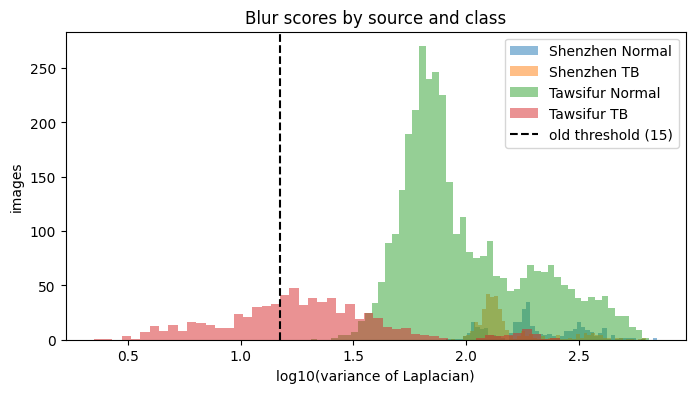

kept 4859 images; cache = 233 MB


In [5]:
def thumb(img):
    """64x64 zero-mean, unit-norm vector: dot product of two thumbs = Pearson correlation."""
    v = cv2.resize(img, (64, 64), interpolation=cv2.INTER_AREA).astype(np.float32).ravel()
    v -= v.mean(); return v / (np.linalg.norm(v) + 1e-8)

def process(path):
    try:
        raw = open(path, "rb").read()
        Image.open(io.BytesIO(raw)).verify()                       # unreadable file -> corrupt
        arr = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_GRAYSCALE)
        if arr is None: return dict(status="corrupt")
        b = arr if BLUR_RES is None else cv2.resize(arr, (BLUR_RES, BLUR_RES), interpolation=cv2.INTER_AREA)
        blur = float(cv2.Laplacian(b, cv2.CV_64F).var())
        small = cv2.resize(arr, (IMG, IMG), interpolation=cv2.INTER_AREA)
        return dict(status="ok", md5=hashlib.md5(raw).hexdigest(), blur=blur, img=small, thumb=thumb(small))
    except Exception:
        return dict(status="corrupt")

t0 = time.time()
with ThreadPoolExecutor(LOAD_WORKERS) as ex:
    out = list(ex.map(process, raw_df.path.tolist()))
print(f"decoded {len(out)} images in {time.time()-t0:.0f}s")

raw_df["status"] = [o["status"] for o in out]
raw_df["blur"]   = [o.get("blur", np.nan) for o in out]
raw_df["md5"]    = [o.get("md5") for o in out]
if BLUR_THRESHOLD:
    raw_df.loc[(raw_df.status == "ok") & (raw_df.blur < BLUR_THRESHOLD), "status"] = "blurry"

# exact duplicates (anywhere in the pool): keep the first copy; if copies disagree on label, drop all
ok = raw_df.status == "ok"
conflict = raw_df[ok].groupby("md5").label.nunique()
conflict_md5 = set(conflict[conflict > 1].index)
raw_df.loc[ok & raw_df.md5.isin(conflict_md5), "status"] = "label_conflict"
ok = raw_df.status == "ok"
raw_df.loc[ok & raw_df.duplicated("md5", keep="first"), "status"] = "duplicate"

summary = raw_df.groupby(["source", "label", "status"]).size().unstack(fill_value=0)
print(summary.to_string())
summary.to_csv(os.path.join(OUT_DIR, "cleaning_summary.csv"))

# blur-score distribution: check that the filter does not remove one class much more than the other
plt.figure(figsize=(8, 4))
for (src, lab), g in raw_df[raw_df.blur.notna()].groupby(["source", "label"]):
    plt.hist(np.log10(g.blur + 1e-6), bins=50, alpha=0.5, label=f"{src} {'TB' if lab else 'Normal'}")
plt.axvline(np.log10(15.0), color="k", ls="--", label="old threshold (15)")
plt.xlabel("log10(variance of Laplacian)"); plt.ylabel("images"); plt.legend(); plt.title("Blur scores by source and class")
savefig("blur_distribution.png"); plt.show()

keep = raw_df.status == "ok"
df = raw_df[keep].reset_index(drop=True)
IMGS = np.stack([out[i]["img"] for i in np.where(keep)[0]])          # [N,224,224] uint8
THUMB = np.stack([out[i]["thumb"] for i in np.where(keep)[0]])       # [N,4096] float32
del out
print(f"kept {len(df)} images; cache = {IMGS.nbytes/2**20:.0f} MB")

## 5. Train / validation / test split and federated clients

near-duplicates removed from val/test: 3
max correlation of val/test images to the training set, quantiles 50/90/99/100%: [0.8998 0.9361 0.9583 1.    ]


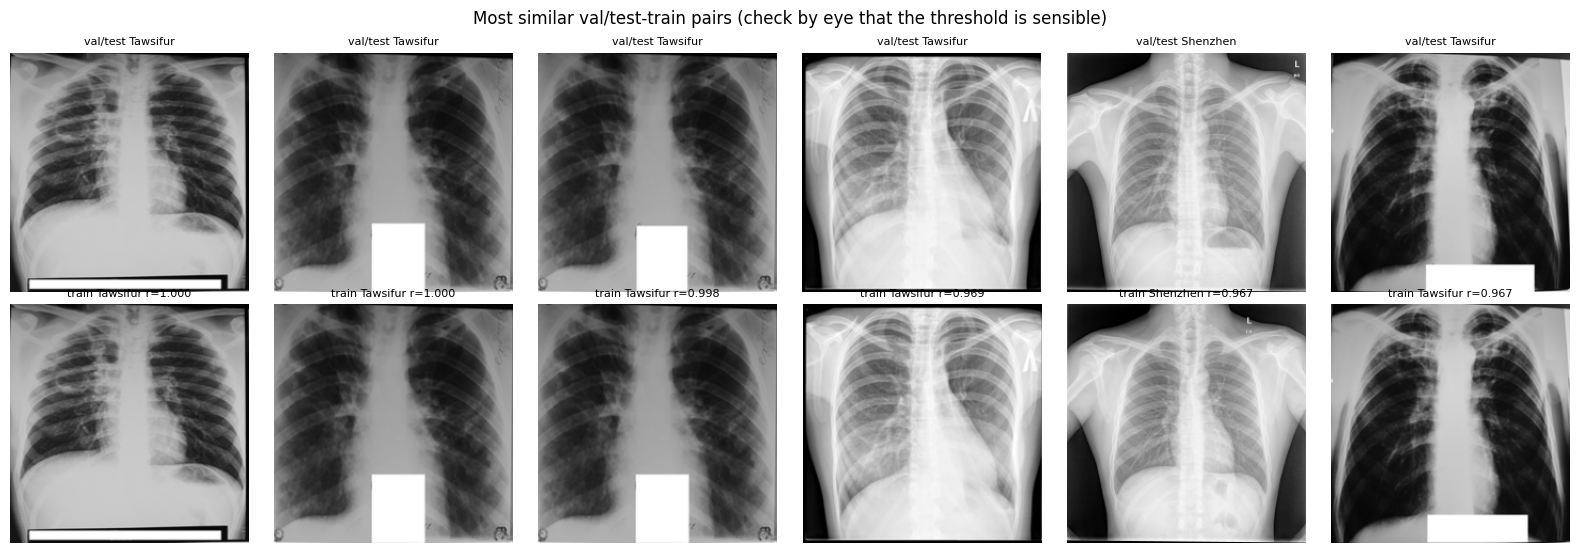

Leakage checks passed (paths, MD5, near-duplicate correlation).
                       set            sources  TB  Normal  Total
       Client A (Tawsifur)           Tawsifur 488     488    976
       Client B (Shenzhen)           Shenzhen 235     228    463
Client C (Tawsifur normal)           Tawsifur   0    1000   1000
                Validation Shenzhen, Tawsifur 102     102    204
                      Test Shenzhen, Tawsifur 205     202    407
split id: 69149d0a (saved runs are only reused for exactly this split)
source    label
Shenzhen  0         65
          1         68
Tawsifur  0        137
          1        137


In [6]:
rng = np.random.default_rng(DATA_SEED)
df["split"] = ""
for src, g in df.groupby("source"):
    strat = g.label if g.label.nunique() > 1 else None
    tr, tmp = train_test_split(g.index, test_size=SPLIT[1] + SPLIT[2], stratify=strat, random_state=DATA_SEED)
    strat2 = df.loc[tmp, "label"] if strat is not None else None
    va, te = train_test_split(tmp, test_size=SPLIT[2] / (SPLIT[1] + SPLIT[2]), stratify=strat2, random_state=DATA_SEED)
    df.loc[tr, "split"], df.loc[va, "split"], df.loc[te, "split"] = "train", "val", "test"

# near-duplicate guard (BEFORE balancing): a val/test image is removed only if it is almost pixel-identical
# to a training image (max Pearson correlation of 64x64 thumbnails >= NEAR_DUP_CORR)
tr_all = df.index[df.split == "train"].to_numpy(); ev_all = df.index[df.split.isin(["val", "test"])].to_numpy()
best_corr, best_match = np.empty(len(ev_all)), np.empty(len(ev_all), int)
for k in range(0, len(ev_all), 256):
    C = THUMB[ev_all[k:k + 256]] @ THUMB[tr_all].T
    best_corr[k:k + 256] = C.max(1); best_match[k:k + 256] = tr_all[C.argmax(1)]
near = best_corr >= NEAR_DUP_CORR
df.loc[ev_all[near], "split"] = "unused"; n_near = int(near.sum())
print(f"near-duplicates removed from val/test: {n_near}")
print("max correlation of val/test images to the training set, quantiles 50/90/99/100%:",
      np.round(np.quantile(best_corr, [.5, .9, .99, 1.0]), 4))
nd = pd.DataFrame(dict(eval_path=df.loc[ev_all, "path"].values, eval_source=df.loc[ev_all, "source"].values,
                       train_path=df.loc[best_match, "path"].values, train_source=df.loc[best_match, "source"].values,
                       corr=best_corr)).sort_values("corr", ascending=False)
nd.head(200).to_csv(os.path.join(OUT_DIR, "near_duplicate_candidates.csv"), index=False)
top = np.argsort(-best_corr)[:6]
fig, ax = plt.subplots(2, 6, figsize=(16, 5.6))
for c, t in enumerate(top):
    ax[0, c].imshow(IMGS[ev_all[t]], cmap="gray"); ax[0, c].set_title(f"val/test {df.source[ev_all[t]]}", fontsize=8)
    ax[1, c].imshow(IMGS[best_match[t]], cmap="gray"); ax[1, c].set_title(f"train {df.source[best_match[t]]} r={best_corr[t]:.3f}", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Most similar val/test-train pairs (check by eye that the threshold is sensible)"); plt.tight_layout()
savefig("near_duplicate_pairs.png"); plt.show()

# Tawsifur has 5x more normals than TB: make its val/test parts balanced (extra normals are not used)
for sp in ("val", "test"):
    tb = df[(df.source == "Tawsifur") & (df.split == sp) & (df.label == 1)]
    nm = df[(df.source == "Tawsifur") & (df.split == sp) & (df.label == 0)]
    drop = rng.choice(nm.index, size=max(len(nm) - len(tb), 0), replace=False)
    df.loc[drop, "split"] = "unused"

# ---- clients (training images only)
tr = df[df.split == "train"]
tw_tb = tr[(tr.source == "Tawsifur") & (tr.label == 1)].index.to_numpy()
tw_nm = rng.permutation(tr[(tr.source == "Tawsifur") & (tr.label == 0)].index.to_numpy())
client_idx = {
    "Client A (Tawsifur)": np.concatenate([tw_tb, tw_nm[: len(tw_tb)]]),
    "Client B (Shenzhen)": tr[tr.source == "Shenzhen"].index.to_numpy(),
}
if CLIENT_C_SOURCE == "tawsifur":
    c_pool = tw_nm[len(tw_tb):]
else:
    c_pool = rng.permutation(tr[tr.source == "NIH"].index.to_numpy())
client_idx[f"Client C ({'Tawsifur' if CLIENT_C_SOURCE == 'tawsifur' else 'NIH'} normal)"] = c_pool[:CLIENT_C_SIZE]
used_train = np.concatenate(list(client_idx.values()))
df.loc[df.index.isin(df.index[df.split == "train"].difference(used_train)), "split"] = "unused"

val_idx  = df.index[df.split == "val"].to_numpy()
test_idx = df.index[df.split == "test"].to_numpy()

# ---- sanity checks: no image in two places
all_sets = list(client_idx.values()) + [val_idx, test_idx]
flat = np.concatenate(all_sets)
assert len(flat) == len(set(flat)), "an image appears in two sets"
assert not set(df.loc[test_idx, "md5"]) & set(df.loc[used_train, "md5"]), "MD5 overlap train/test"
assert not set(df.loc[test_idx, "path"]) & set(df.loc[used_train, "path"]), "path overlap train/test"
print("Leakage checks passed (paths, MD5, near-duplicate correlation).")

rows = []
for name, idx in client_idx.items():
    s = df.loc[idx]
    rows.append(dict(set=name, sources=", ".join(sorted(s.source.unique())), TB=int((s.label == 1).sum()),
                     Normal=int((s.label == 0).sum()), Total=len(s)))
for name, idx in (("Validation", val_idx), ("Test", test_idx)):
    s = df.loc[idx]
    rows.append(dict(set=name, sources=", ".join(sorted(s.source.unique())), TB=int((s.label == 1).sum()),
                     Normal=int((s.label == 0).sum()), Total=len(s)))
TABLE1 = pd.DataFrame(rows); print(TABLE1.to_string(index=False))
SPLIT_ID = hashlib.md5("|".join(sorted(df.loc[used_train, "path"])) .encode() + b"#" +
                       "|".join(sorted(df.loc[np.concatenate([val_idx, test_idx]), "path"])).encode()).hexdigest()[:8]
RUN_DIR = os.path.join(OUT_DIR, "runs", SPLIT_ID); os.makedirs(RUN_DIR, exist_ok=True)
print("split id:", SPLIT_ID, "(saved runs are only reused for exactly this split)")
TABLE1.to_csv(os.path.join(OUT_DIR, "table1_data_distribution.csv"), index=False)
print(df.loc[test_idx].groupby(["source", "label"]).size().rename("test images").to_string())

## 6. Tensors and batching

In [7]:
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

class Split:
    def __init__(self, idx):
        self.idx = np.asarray(idx)
        self.X = torch.from_numpy(IMGS[self.idx])                    # uint8 [N,224,224]
        self.y = torch.tensor(df.loc[self.idx, "label"].values, dtype=torch.long)
        self.source = df.loc[self.idx, "source"].values
        self.path = df.loc[self.idx, "path"].values
    def __len__(self): return len(self.y)

def to_input(xb):
    """uint8 [B,224,224] -> ImageNet-normalised float [B,3,224,224] (grey replicated to RGB)."""
    x = xb.to(device, non_blocking=True).float().div_(255).unsqueeze(1).expand(-1, 3, -1, -1)
    return (x - MEAN) / STD

def batches(split, bs, shuffle, gen=None):
    n = len(split)
    order = torch.randperm(n, generator=gen) if shuffle else torch.arange(n)
    for i in range(0, n, bs):
        j = order[i:i + bs]
        yield to_input(split.X[j]), split.y[j].to(device)

CLIENTS = {name: Split(idx) for name, idx in client_idx.items()}
POOLED  = Split(used_train)
VAL, TEST = Split(val_idx), Split(test_idx)
y_test = TEST.y.numpy()
print({k: len(v) for k, v in CLIENTS.items()}, "| val", len(VAL), "| test", len(TEST))

{'Client A (Tawsifur)': 976, 'Client B (Shenzhen)': 463, 'Client C (Tawsifur normal)': 1000} | val 204 | test 407


## 7. Models (proposed model and the ablation baseline)

In [8]:
def densenet_features():
    w = models.DenseNet121_Weights.IMAGENET1K_V1 if PRETRAINED else None
    return models.densenet121(weights=w).features                   # output [B,1024,7,7]

class DenseNetAttention(nn.Module):
    """Proposed model (paper Table II): DenseNet121 -> 49 tokens -> 8-head self-attention -> mean -> FC head."""
    def __init__(self, num_classes=2, heads=8, p_drop=0.4):
        super().__init__()
        self.backbone = densenet_features()
        self.attention = nn.MultiheadAttention(embed_dim=1024, num_heads=heads)
        self.fc = nn.Sequential(nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(256, num_classes))
    def forward_features(self, x): return self.backbone(x)
    def embed(self, feats):
        tokens = feats.flatten(2).permute(2, 0, 1)                   # [49,B,1024]
        attn, _ = self.attention(tokens, tokens, tokens, need_weights=False)
        return attn.mean(0)                                          # [B,1024]
    def forward_head(self, feats): return self.fc(self.embed(feats))
    def forward(self, x): return self.forward_head(self.forward_features(x))

class DenseNetBaseline(DenseNetAttention):
    """Ablation: identical model with the attention layer removed (mean over the same 49 tokens)."""
    def __init__(self, num_classes=2, p_drop=0.4):
        super().__init__(num_classes=num_classes, p_drop=p_drop)
        del self.attention
    def embed(self, feats): return feats.flatten(2).mean(2)

def n_params(m): return sum(p.numel() for p in m.parameters())
for cls in (DenseNetBaseline, DenseNetAttention):
    print(f"{cls.__name__}: {n_params(cls()):,} parameters")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 164MB/s]


DenseNetBaseline: 7,216,770 parameters
DenseNetAttention: 11,415,170 parameters


## 8. Training, FedAvg, prediction and metric functions

In [9]:
def make_scaler():
    try:    return torch.amp.GradScaler("cuda", enabled=AMP_ON)
    except Exception: return torch.cuda.amp.GradScaler(enabled=AMP_ON)

def train_epochs(model, split, epochs, opt, scaler, gen):
    model.train(); tot_loss = tot_ok = tot = 0
    for _ in range(epochs):
        for xb, yb in batches(split, BATCH_SIZE, True, gen):
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ON):
                out = model(xb); loss = F.cross_entropy(out, yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot_loss += loss.item() * len(yb); tot_ok += (out.argmax(1) == yb).sum().item(); tot += len(yb)
    return tot_loss / tot, tot_ok / tot

def local_train(global_model, split, seed):
    """One client update: copy of the global model, LOCAL_EPOCHS of Adam on the client's own data."""
    model = copy.deepcopy(global_model)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss, acc = train_epochs(model, split, LOCAL_EPOCHS, opt, make_scaler(), torch.Generator().manual_seed(seed))
    state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    del model, opt
    return state, len(split), loss, acc

def fedavg(states, sizes):
    w = np.asarray(sizes, float)
    w = w / w.sum() if WEIGHTED_FEDAVG else np.full(len(states), 1 / len(states))
    avg = {}
    for k in states[0]:
        if states[0][k].is_floating_point():
            avg[k] = sum(float(wi) * s[k] for wi, s in zip(w, states))
        else:                                  # integer buffers (BatchNorm num_batches_tracked)
            avg[k] = states[0][k].clone()
    return avg

@torch.no_grad()
def predict(model, split, bs=64):
    model.eval(); probs, loss = [], 0.0
    for xb, yb in batches(split, bs, False):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=AMP_ON):
            out = model(xb)
        out = out.float()
        loss += F.cross_entropy(out, yb, reduction="sum").item()
        probs.append(torch.softmax(out, 1)[:, 1].cpu())
    return torch.cat(probs).numpy(), loss / len(split)

def ece_score(y, p, n_bins=10):
    """Standard (sample-weighted) expected calibration error of the TB probability."""
    edges = np.linspace(0, 1, n_bins + 1)
    ids = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum((ids == b).mean() * abs(y[ids == b].mean() - p[ids == b].mean())
                     for b in range(n_bins) if (ids == b).any()))

def compute_metrics(y, p, thr=0.5):
    y = np.asarray(y); p = np.asarray(p); yh = (p >= thr).astype(int)
    tn, fp, fn, tp = skm.confusion_matrix(y, yh, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return dict(n=len(y), tp=int(tp), fn=int(fn), tn=int(tn), fp=int(fp),
                accuracy=(tp + tn) / len(y),
                sensitivity=tp / (tp + fn) if tp + fn else np.nan,
                specificity=tn / (tn + fp) if tn + fp else np.nan,
                precision=tp / (tp + fp) if tp + fp else np.nan,
                f1=skm.f1_score(y, yh, zero_division=0),
                auc=skm.roc_auc_score(y, p) if both else np.nan,
                ap=skm.average_precision_score(y, p) if both else np.nan,
                kappa=skm.cohen_kappa_score(y, yh), mcc=skm.matthews_corrcoef(y, yh),
                brier=skm.brier_score_loss(y, p), ece=ece_score(y, p))

def _light(y, p):
    yh = p >= 0.5; tp = (yh & (y == 1)).sum(); tn = (~yh & (y == 0)).sum()
    P = (y == 1).sum(); N = (y == 0).sum(); fp = N - tn
    return dict(accuracy=(tp + tn) / len(y), sensitivity=tp / P, specificity=tn / N,
                f1=2 * tp / (2 * tp + fp + (P - tp)), auc=skm.roc_auc_score(y, p))

def bootstrap_ci(y, p, n=N_BOOT, seed=0):
    rng = np.random.default_rng(seed); vals = {}
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        for k, v in _light(y[i], p[i]).items(): vals.setdefault(k, []).append(v)
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in vals.items()}

def paired_bootstrap_diff(y, p_a, p_b, n=N_BOOT, seed=0):
    """CI of (model A - model B) for accuracy and AUC, resampling the same test images for both."""
    rng = np.random.default_rng(seed); d = {"accuracy": [], "auc": []}
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        a, b = _light(y[i], p_a[i]), _light(y[i], p_b[i])
        for k in d: d[k].append(a[k] - b[k])
    return {k: (float(np.mean(v)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in d.items()}

def mcnemar_exact(y, p_a, p_b):
    ca, cb = (p_a >= .5) == y, (p_b >= .5) == y
    b, c = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return b, c, (stats.binomtest(min(b, c), b + c, 0.5).pvalue if b + c else 1.0)

## 9. Federated and centralised training loops

In [10]:
def snapshot(model): return {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

def run_federated(model_cls, seed):
    set_seed(seed)
    gmodel = model_cls().to(device)
    hist, best = [], dict(val_loss=np.inf)
    for r in range(1, NUM_ROUNDS + 1):
        t0 = time.time(); states, sizes, rec = [], [], dict(round=r)
        for ci, (name, split) in enumerate(CLIENTS.items()):
            s, n, l, a = local_train(gmodel, split, seed * 10_000 + r * 10 + ci)
            states.append(s); sizes.append(n)
            rec[f"{name} loss"], rec[f"{name} acc"] = l, a
        gmodel.load_state_dict(fedavg(states, sizes)); del states
        w = np.asarray(sizes) / sum(sizes)
        rec["train_loss"] = float(sum(wi * rec[f"{n} loss"] for wi, n in zip(w, CLIENTS)))
        rec["train_acc"]  = float(sum(wi * rec[f"{n} acc"]  for wi, n in zip(w, CLIENTS)))
        pv, vloss = predict(gmodel, VAL); vm = compute_metrics(VAL.y.numpy(), pv)
        rec.update(val_loss=vloss, val_acc=vm["accuracy"], val_auc=vm["auc"], seconds=time.time() - t0)
        hist.append(rec)
        print(f"  round {r:2d} | train loss {rec['train_loss']:.4f} acc {rec['train_acc']:.4f} | "
              f"val loss {vloss:.4f} acc {vm['accuracy']:.4f} auc {vm['auc']:.4f} | {rec['seconds']:.0f}s")
        if vloss < best["val_loss"]:
            best = dict(val_loss=vloss, round=r, state=snapshot(gmodel))
    gmodel.load_state_dict(best["state"])
    return gmodel, pd.DataFrame(hist), best["round"]

def run_centralised(model_cls, seed):
    """Pooled training with the same budget: NUM_ROUNDS * LOCAL_EPOCHS passes over all client data."""
    set_seed(seed)
    model = model_cls().to(device)
    opt, scaler, gen = torch.optim.Adam(model.parameters(), lr=LR), make_scaler(), torch.Generator().manual_seed(seed)
    hist, best = [], dict(val_loss=np.inf)
    for ep in range(1, NUM_ROUNDS * LOCAL_EPOCHS + 1):
        t0 = time.time()
        l, a = train_epochs(model, POOLED, 1, opt, scaler, gen)
        pv, vloss = predict(model, VAL); vm = compute_metrics(VAL.y.numpy(), pv)
        hist.append(dict(round=ep, train_loss=l, train_acc=a, val_loss=vloss, val_acc=vm["accuracy"],
                         val_auc=vm["auc"], seconds=time.time() - t0))
        print(f"  epoch {ep:2d} | train loss {l:.4f} | val loss {vloss:.4f} acc {vm['accuracy']:.4f}")
        if vloss < best["val_loss"]:
            best = dict(val_loss=vloss, round=ep, state=snapshot(model))
    model.load_state_dict(best["state"])
    return model, pd.DataFrame(hist), best["round"]

## 10. Run all experiments (3 seeds × {FL baseline, FL proposed, centralised proposed})

In [11]:
PROPOSED, BASELINE, CENTRAL = "FL DenseNet121+Attention", "FL DenseNet121 (no attention)", "Centralised DenseNet121+Attention"
EXPERIMENTS = [(BASELINE, DenseNetBaseline, run_federated), (PROPOSED, DenseNetAttention, run_federated)]
if RUN_CENTRALISED:
    EXPERIMENTS.append((CENTRAL, DenseNetAttention, run_centralised))

def run_file(name, seed, ext):
    return os.path.join(RUN_DIR, re.sub(r"[^A-Za-z0-9]+", "_", name) + f"_seed{seed}.{ext}")

RESULTS = {}
for seed in SEEDS:
    for name, cls, runner in EXPERIMENTS:
        f_pkl, f_pt = run_file(name, seed, "pkl"), run_file(name, seed, "pt")
        if RESUME and os.path.exists(f_pkl) and os.path.exists(f_pt):
            RESULTS[(name, seed)] = pickle.load(open(f_pkl, "rb")); print(f"[loaded] {name} seed {seed}"); continue
        print(f"\n=== {name} | seed {seed} ===")
        t0 = time.time()
        model, hist, best_round = runner(cls, seed)
        p_test, _ = predict(model, TEST)
        res = dict(p_test=p_test, hist=hist, best_round=best_round, minutes=(time.time() - t0) / 60,
                   metrics=compute_metrics(y_test, p_test))
        torch.save(model.state_dict(), f_pt); pickle.dump(res, open(f_pkl, "wb"))
        hist.to_csv(run_file(name, seed, "csv"), index=False)
        RESULTS[(name, seed)] = res
        print(f"best round {best_round} | test acc {res['metrics']['accuracy']:.4f} auc {res['metrics']['auc']:.4f} "
              f"| {res['minutes']:.1f} min")
        del model; torch.cuda.empty_cache()

# per-image predictions for every run (lets you recompute anything later)
pred_df = pd.DataFrame(dict(path=TEST.path, source=TEST.source, label=y_test))
for (name, seed), r in RESULTS.items(): pred_df[f"{name} | seed {seed}"] = r["p_test"]
pred_df.to_csv(os.path.join(OUT_DIR, "test_predictions_all_runs.csv"), index=False)

MAIN_SEED = SEEDS[0]
MAIN_MODEL = DenseNetAttention().to(device)
MAIN_MODEL.load_state_dict(torch.load(run_file(PROPOSED, MAIN_SEED, "pt"), map_location=device)); MAIN_MODEL.eval()
p_main = RESULTS[(PROPOSED, MAIN_SEED)]["p_test"]


=== FL DenseNet121 (no attention) | seed 0 ===
  round  1 | train loss 0.1840 acc 0.9473 | val loss 0.4944 acc 0.8235 auc 0.9007 | 28s
  round  2 | train loss 0.1008 acc 0.9635 | val loss 0.4948 acc 0.8284 auc 0.9422 | 24s
  round  3 | train loss 0.0761 acc 0.9731 | val loss 0.4884 acc 0.8333 auc 0.9125 | 24s
  round  4 | train loss 0.0767 acc 0.9758 | val loss 0.7761 acc 0.8333 auc 0.8548 | 25s
  round  5 | train loss 0.0831 acc 0.9733 | val loss 0.6238 acc 0.8382 auc 0.9170 | 26s
  round  6 | train loss 0.0552 acc 0.9811 | val loss 0.9133 acc 0.8382 auc 0.8714 | 25s
  round  7 | train loss 0.0587 acc 0.9803 | val loss 0.4898 acc 0.8480 auc 0.9136 | 25s
  round  8 | train loss 0.0599 acc 0.9838 | val loss 0.7441 acc 0.8431 auc 0.8962 | 25s
  round  9 | train loss 0.0800 acc 0.9836 | val loss 0.9424 acc 0.8284 auc 0.8357 | 25s
  round 10 | train loss 0.0579 acc 0.9840 | val loss 0.4129 acc 0.8529 auc 0.9249 | 25s
  round 11 | train loss 0.0608 acc 0.9859 | val loss 0.4901 acc 0.8627 a

## 11. Results tables (paper Table IV and Table V)

In [12]:
KEYS = ["accuracy", "sensitivity", "specificity", "precision", "f1", "auc", "ap", "kappa", "mcc", "ece", "brier"]
n_par = {PROPOSED: n_params(DenseNetAttention()), BASELINE: n_params(DenseNetBaseline()), CENTRAL: n_params(DenseNetAttention())}
rows = []
for name, _, _ in EXPERIMENTS:
    ms = pd.DataFrame([RESULTS[(name, s)]["metrics"] for s in SEEDS])
    row = {"model": name, "params (M)": round(n_par[name] / 1e6, 2),
           "best round (per seed)": ", ".join(str(RESULTS[(name, s)]["best_round"]) for s in SEEDS)}
    for k in KEYS: row[k] = f"{ms[k].mean():.4f} ± {ms[k].std(ddof=1) if len(SEEDS) > 1 else 0:.4f}"
    rows.append(row)
TABLE_ABLATION = pd.DataFrame(rows)
print("Mean ± SD over seeds", SEEDS); print(TABLE_ABLATION.to_string(index=False))
TABLE_ABLATION.to_csv(os.path.join(OUT_DIR, "table5_ablation_mean_sd.csv"), index=False)

# main model (seed MAIN_SEED) with 95% bootstrap CIs
m_main = RESULTS[(PROPOSED, MAIN_SEED)]["metrics"]; ci_main = bootstrap_ci(y_test, p_main)
TABLE_MAIN = pd.DataFrame([dict(metric=k, value=round(m_main[k], 4),
                                ci95=(f"[{ci_main[k][0]:.4f}, {ci_main[k][1]:.4f}]" if k in ci_main else ""))
                           for k in KEYS])
print(f"\nProposed model, seed {MAIN_SEED}, test n={m_main['n']}: TP={m_main['tp']} FN={m_main['fn']} TN={m_main['tn']} FP={m_main['fp']}")
print(TABLE_MAIN.to_string(index=False))
TABLE_MAIN.to_csv(os.path.join(OUT_DIR, "table4_main_model_ci.csv"), index=False)

# performance per data source (does the model work on each hospital separately?)
per_src = []
for src in np.unique(TEST.source):
    m = TEST.source == src
    r = compute_metrics(y_test[m], p_main[m]); r["source"] = src; per_src.append(r)
TABLE_SOURCE = pd.DataFrame(per_src)[["source", "n", "accuracy", "sensitivity", "specificity", "auc"]]
print("\nPer-source test performance (proposed, main seed):"); print(TABLE_SOURCE.round(4).to_string(index=False))
TABLE_SOURCE.to_csv(os.path.join(OUT_DIR, "table_per_source.csv"), index=False)

Mean ± SD over seeds [0, 1, 2]
                            model  params (M) best round (per seed)        accuracy     sensitivity     specificity       precision              f1             auc              ap           kappa             mcc             ece           brier
    FL DenseNet121 (no attention)        7.22             10, 14, 9 0.8788 ± 0.0228 0.8276 ± 0.0750 0.9307 ± 0.0301 0.9258 ± 0.0262 0.8719 ± 0.0320 0.9496 ± 0.0189 0.9606 ± 0.0138 0.7578 ± 0.0454 0.7645 ± 0.0351 0.0674 ± 0.0283 0.0921 ± 0.0215
         FL DenseNet121+Attention       11.42               7, 2, 9 0.8493 ± 0.0178 0.7057 ± 0.0394 0.9950 ± 0.0050 0.9934 ± 0.0064 0.8247 ± 0.0247 0.9458 ± 0.0339 0.9587 ± 0.0244 0.6992 ± 0.0354 0.7312 ± 0.0272 0.1438 ± 0.0185 0.1364 ± 0.0205
Centralised DenseNet121+Attention       11.42            23, 16, 28 0.9672 ± 0.0121 0.9577 ± 0.0269 0.9769 ± 0.0057 0.9769 ± 0.0052 0.9670 ± 0.0127 0.9943 ± 0.0037 0.9950 ± 0.0028 0.9345 ± 0.0242 0.9350 ± 0.0235 0.0235 ± 0.0038 0.0262 ± 

## 12. Statistical comparison: proposed vs. baseline 

In [13]:
stat_rows = []
for s in SEEDS:
    pa, pb = RESULTS[(PROPOSED, s)]["p_test"], RESULTS[(BASELINE, s)]["p_test"]
    b, c, p = mcnemar_exact(y_test, pa, pb)
    d = paired_bootstrap_diff(y_test, pa, pb, seed=s)
    stat_rows.append(dict(seed=s, only_proposed_correct=b, only_baseline_correct=c, mcnemar_p=p,
                          d_acc=d["accuracy"][0], d_acc_ci=f"[{d['accuracy'][1]:.4f}, {d['accuracy'][2]:.4f}]",
                          d_auc=d["auc"][0], d_auc_ci=f"[{d['auc'][1]:.4f}, {d['auc'][2]:.4f}]"))
TABLE_STATS = pd.DataFrame(stat_rows)
print(TABLE_STATS.round(4).to_string(index=False))
TABLE_STATS.to_csv(os.path.join(OUT_DIR, "table_stats_mcnemar_bootstrap.csv"), index=False)
print("\nReport the difference as significant only if McNemar p < 0.05 AND the bootstrap CI excludes 0 for every seed.")

 seed  only_proposed_correct  only_baseline_correct  mcnemar_p   d_acc           d_acc_ci   d_auc           d_auc_ci
    0                     14                      7     0.1892  0.0173  [-0.0049, 0.0394]  0.0381   [0.0186, 0.0605]
    1                     16                     37     0.0055 -0.0513 [-0.0860, -0.0172] -0.0565 [-0.0785, -0.0389]
    2                     18                     40     0.0054 -0.0542 [-0.0910, -0.0171]  0.0078  [-0.0080, 0.0234]

Report the difference as significant only if McNemar p < 0.05 AND the bootstrap CI excludes 0 for every seed.


## 13. Federated convergence from the real training log

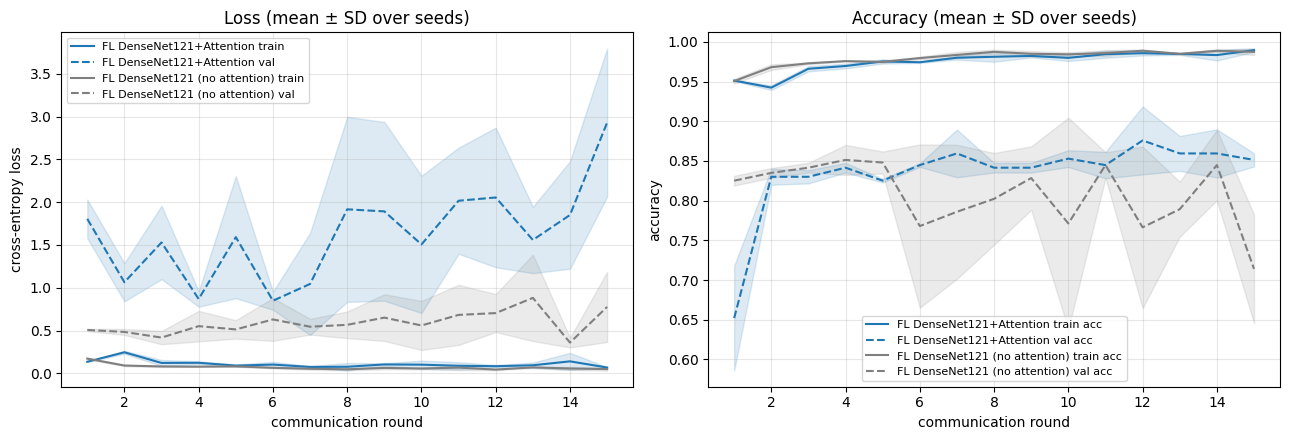

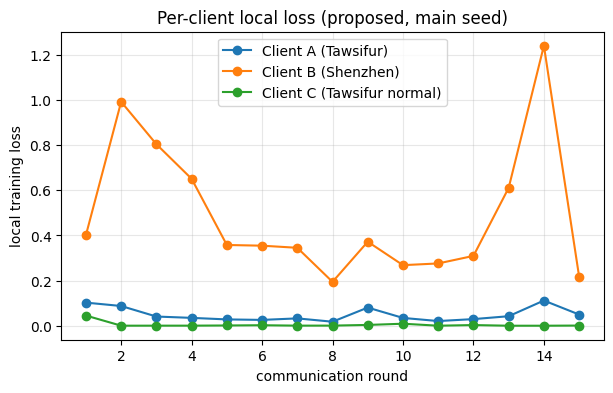

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, col in ((PROPOSED, "tab:blue"), (BASELINE, "tab:gray")):
    H = [RESULTS[(name, s)]["hist"] for s in SEEDS]
    r = H[0]["round"].values
    for key, ls, lab in (("train_loss", "-", "train"), ("val_loss", "--", "val")):
        a = np.stack([h[key].values for h in H]); m, sd = a.mean(0), a.std(0)
        ax[0].plot(r, m, ls, color=col, label=f"{name} {lab}"); ax[0].fill_between(r, m - sd, m + sd, color=col, alpha=.15)
    for key, ls, lab in (("train_acc", "-", "train acc"), ("val_acc", "--", "val acc")):
        a = np.stack([h[key].values for h in H]); m, sd = a.mean(0), a.std(0)
        ax[1].plot(r, m, ls, color=col, label=f"{name} {lab}"); ax[1].fill_between(r, m - sd, m + sd, color=col, alpha=.15)
ax[0].set(xlabel="communication round", ylabel="cross-entropy loss", title="Loss (mean ± SD over seeds)")
ax[1].set(xlabel="communication round", ylabel="accuracy", title="Accuracy (mean ± SD over seeds)")
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); savefig("fig4_convergence.png"); plt.show()

h = RESULTS[(PROPOSED, MAIN_SEED)]["hist"]
plt.figure(figsize=(7, 4))
for name in CLIENTS: plt.plot(h["round"], h[f"{name} loss"], marker="o", label=name)
plt.xlabel("communication round"); plt.ylabel("local training loss"); plt.title("Per-client local loss (proposed, main seed)")
plt.grid(alpha=.3); plt.legend(); savefig("fig4b_client_losses.png"); plt.show()

## 14. Confusion matrix, ROC and PR curves 

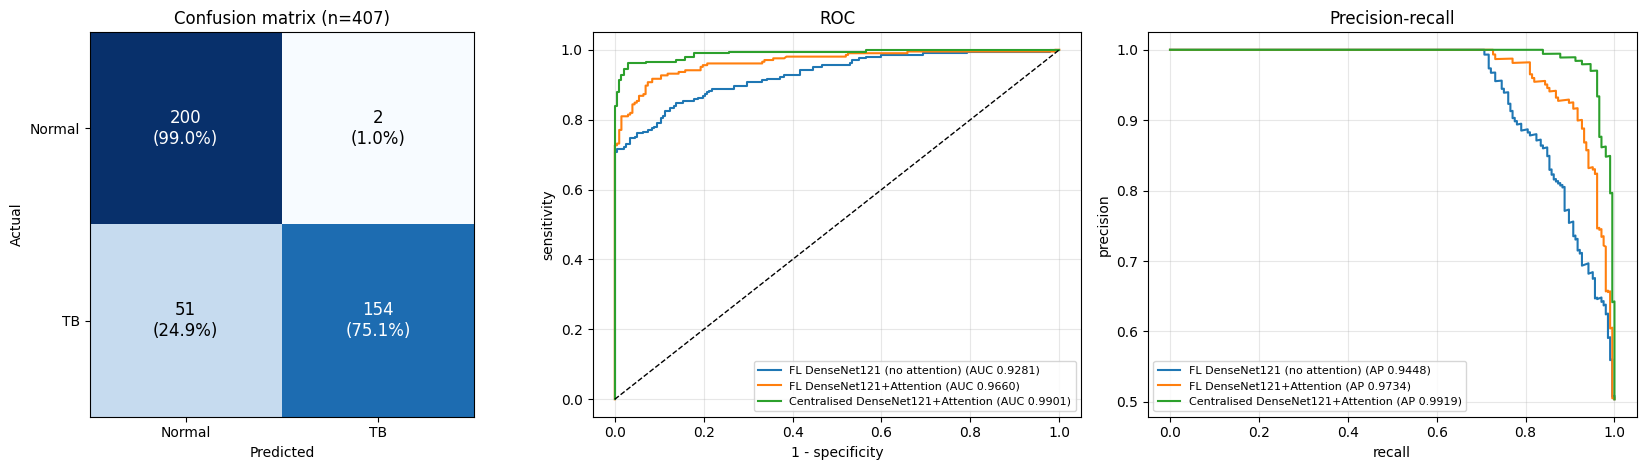

In [15]:
cm = skm.confusion_matrix(y_test, (p_main >= .5).astype(int), labels=[0, 1])
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
im = ax[0].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=12)
ax[0].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Normal", "TB"], yticklabels=["Normal", "TB"],
          xlabel="Predicted", ylabel="Actual", title=f"Confusion matrix (n={len(y_test)})")
for name, _, _ in EXPERIMENTS:
    p = RESULTS[(name, MAIN_SEED)]["p_test"]
    fpr, tpr, _ = skm.roc_curve(y_test, p); pr, rc, _ = skm.precision_recall_curve(y_test, p)
    ax[1].plot(fpr, tpr, label=f"{name} (AUC {skm.roc_auc_score(y_test, p):.4f})")
    ax[2].plot(rc, pr, label=f"{name} (AP {skm.average_precision_score(y_test, p):.4f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set(xlabel="1 - specificity", ylabel="sensitivity", title="ROC"); ax[2].set(xlabel="recall", ylabel="precision", title="Precision-recall")
for a in ax[1:]: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); savefig("fig3_confusion_roc_pr.png"); plt.show()

## 15. Calibration and decision-curve analysis

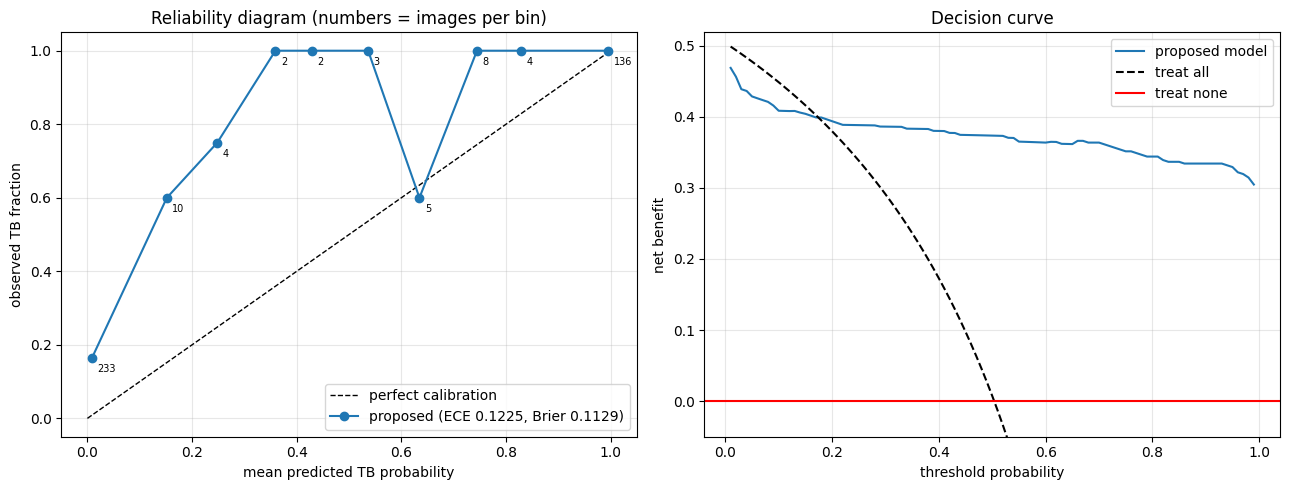

NOTE: test prevalence is fixed by the split design, so net benefit is only illustrative of this test set.


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
edges = np.linspace(0, 1, 11); ids = np.clip(np.digitize(p_main, edges[1:-1]), 0, 9)
conf = [p_main[ids == b].mean() for b in range(10) if (ids == b).any()]
acc  = [y_test[ids == b].mean() for b in range(10) if (ids == b).any()]
cnt  = [(ids == b).sum() for b in range(10) if (ids == b).any()]
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
ax[0].plot(conf, acc, "o-", label=f"proposed (ECE {m_main['ece']:.4f}, Brier {m_main['brier']:.4f})")
for c_, a_, n_ in zip(conf, acc, cnt): ax[0].annotate(str(n_), (c_, a_), textcoords="offset points", xytext=(4, -10), fontsize=7)
ax[0].set(xlabel="mean predicted TB probability", ylabel="observed TB fraction", title="Reliability diagram (numbers = images per bin)")
ax[0].legend(); ax[0].grid(alpha=.3)

th = np.linspace(0.01, 0.99, 99); n = len(y_test); prev = y_test.mean()
nb_model = [((p_main >= t) & (y_test == 1)).sum() / n - ((p_main >= t) & (y_test == 0)).sum() / n * t / (1 - t) for t in th]
nb_all = [prev - (1 - prev) * t / (1 - t) for t in th]
ax[1].plot(th, nb_model, label="proposed model"); ax[1].plot(th, nb_all, "k--", label="treat all"); ax[1].axhline(0, color="r", label="treat none")
ax[1].set(ylim=(-0.05, max(nb_model) + 0.05), xlabel="threshold probability", ylabel="net benefit", title="Decision curve")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); savefig("fig_calibration_dca.png"); plt.show()
print("NOTE: test prevalence is fixed by the split design, so net benefit is only illustrative of this test set.")

## 16. Feature space: t-SNE and a shortcut (data-source) probe

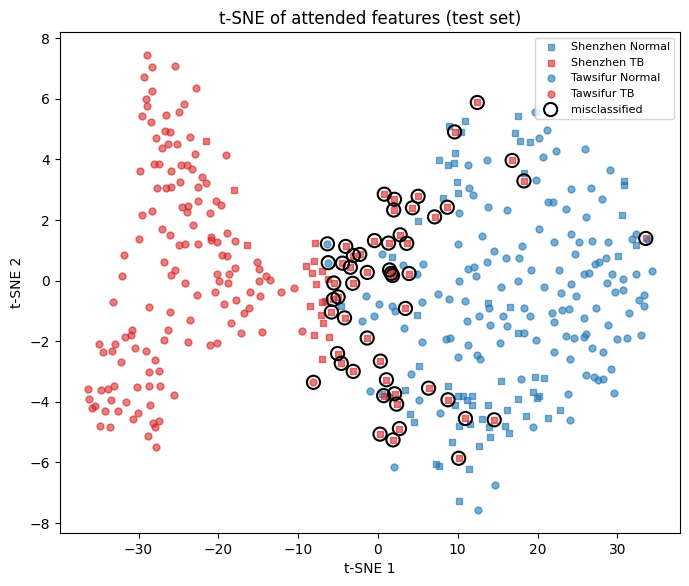

   cls            sources   n  balanced_acc_mean  balanced_acc_sd
Normal Shenzhen, Tawsifur 202              0.939            0.041
    TB Shenzhen, Tawsifur 205              0.974            0.029


In [17]:
@torch.no_grad()
def embeddings(model, split):
    model.eval(); E = []
    for xb, _ in batches(split, 64, False):
        E.append(model.embed(model.forward_features(xb)).float().cpu())
    return torch.cat(E).numpy()

E_test = embeddings(MAIN_MODEL, TEST)
Z = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(E_test)
wrong = (p_main >= .5).astype(int) != y_test
plt.figure(figsize=(8, 6.5))
markers = dict(Tawsifur="o", Shenzhen="s", NIH="^")
for src in np.unique(TEST.source):
    for lab, col in ((0, "tab:blue"), (1, "tab:red")):
        m = (TEST.source == src) & (y_test == lab)
        plt.scatter(Z[m, 0], Z[m, 1], c=col, marker=markers.get(src, "o"), s=25, alpha=.6,
                    label=f"{src} {'TB' if lab else 'Normal'}")
plt.scatter(Z[wrong, 0], Z[wrong, 1], facecolors="none", edgecolors="k", s=90, lw=1.5, label="misclassified")
plt.legend(fontsize=8); plt.title("t-SNE of attended features (test set)"); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2")
savefig("fig5a_tsne.png"); plt.show()

# Shortcut probe: can a linear model tell WHICH HOSPITAL an image came from, within one class?
# Values near 0.5 = features carry little source information; near 1.0 = strong source signal (report it honestly).
probe_rows = []
for lab in (0, 1):
    m = y_test == lab; src = TEST.source[m]
    if len(np.unique(src)) < 2 or min(np.unique(src, return_counts=True)[1]) < 10: continue
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1))
    sc = cross_val_score(clf, E_test[m], src, cv=StratifiedKFold(5, shuffle=True, random_state=0), scoring="balanced_accuracy")
    probe_rows.append(dict(cls="TB" if lab else "Normal", sources=", ".join(np.unique(src)), n=int(m.sum()),
                           balanced_acc_mean=sc.mean(), balanced_acc_sd=sc.std()))
TABLE_PROBE = pd.DataFrame(probe_rows); print(TABLE_PROBE.round(3).to_string(index=False))
TABLE_PROBE.to_csv(os.path.join(OUT_DIR, "table_source_probe.csv"), index=False)

## 17. Grad-CAM with quantitative checks

{
  "n_tb_images": 205,
  "border_energy_mean": 0.245749831199646,
  "border_energy_uniform": 0.35427295918367346,
  "upper_half_energy_mean": 0.38894712924957275,
  "upper_half_uniform": 0.5
}
Border energy well below the uniform value means the maps do not sit on edges/markers.


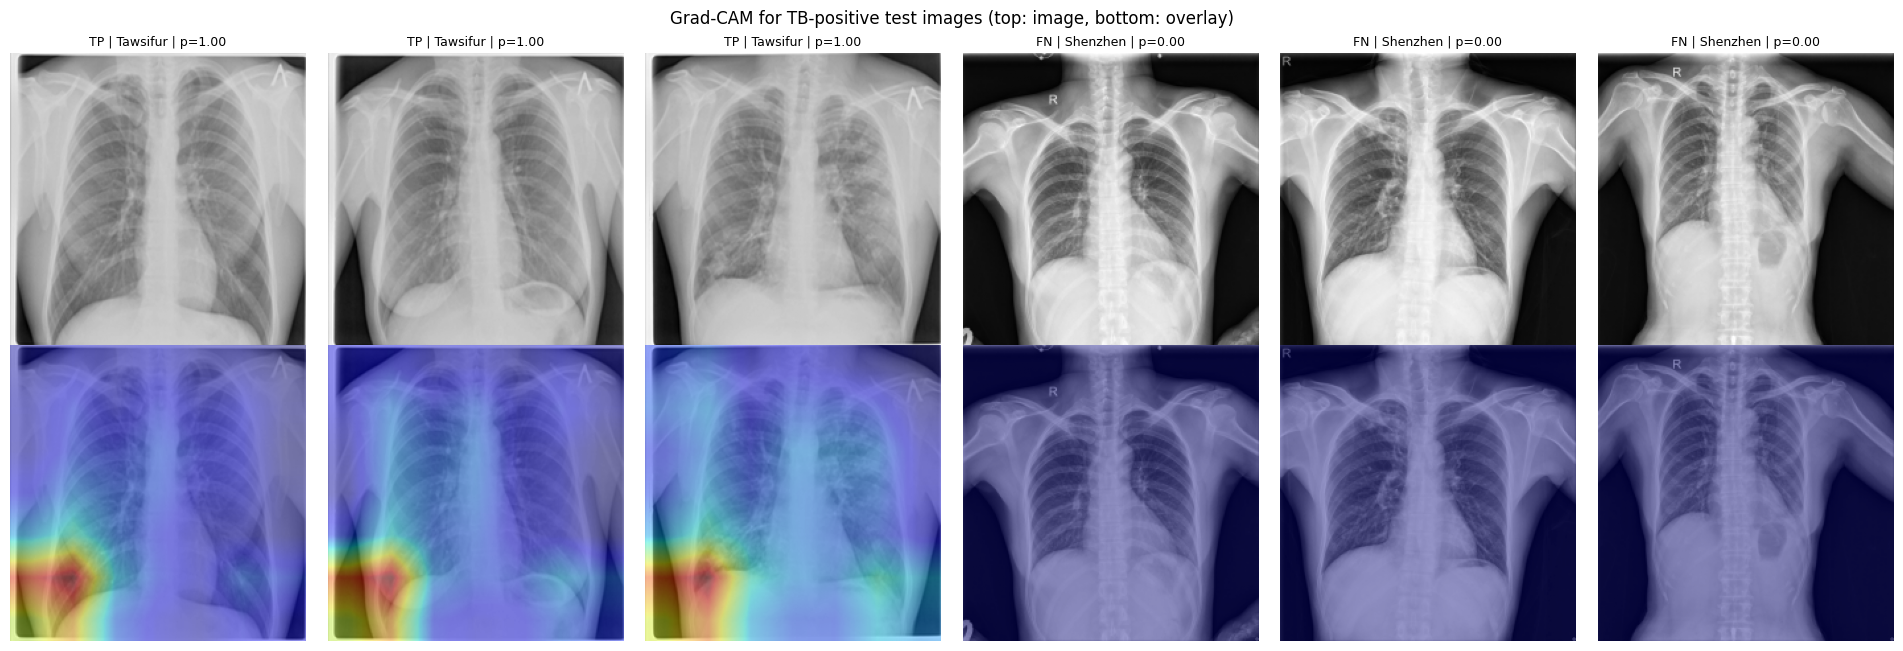

In [18]:
def gradcam(model, x, target=1):
    model.eval()
    with torch.enable_grad():
        feats = model.forward_features(x); feats.retain_grad()
        logits = model.forward_head(feats)
        model.zero_grad(set_to_none=True); logits[:, target].sum().backward()
        w = feats.grad.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * feats).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    cam = cam - cam.amin((1, 2), keepdim=True); cam = cam / (cam.amax((1, 2), keepdim=True) + 1e-8)
    return cam.detach().cpu().numpy()

tb_pos = np.where(y_test == 1)[0]
CAMS = np.concatenate([gradcam(MAIN_MODEL, to_input(TEST.X[tb_pos[i:i + 16]])) for i in range(0, len(tb_pos), 16)])

# (a) share of Grad-CAM energy in a 10% border frame (where text markers / collimation edges sit)
fr = int(0.10 * IMG); frame = np.ones((IMG, IMG), bool); frame[fr:-fr, fr:-fr] = False
border = (CAMS * frame).sum((1, 2)) / (CAMS.sum((1, 2)) + 1e-8)
# (b) share of energy in the upper half of the image
upper = CAMS[:, : IMG // 2].sum((1, 2)) / (CAMS.sum((1, 2)) + 1e-8)
GRADCAM_STATS = dict(n_tb_images=int(len(tb_pos)),
                     border_energy_mean=float(border.mean()), border_energy_uniform=float(frame.mean()),
                     upper_half_energy_mean=float(upper.mean()), upper_half_uniform=0.5)
print(json.dumps(GRADCAM_STATS, indent=2))
print("Border energy well below the uniform value means the maps do not sit on edges/markers.")

pred = (p_main >= .5).astype(int)
tp_idx = [i for i in np.argsort(-p_main) if y_test[i] == 1 and pred[i] == 1][:3]
fn_idx = [i for i in np.argsort(p_main) if y_test[i] == 1 and pred[i] == 0][:3]
show = [(i, "TP") for i in tp_idx] + [(i, "FN") for i in fn_idx]
pos_of = {v: k for k, v in enumerate(tb_pos)}
fig, ax = plt.subplots(2, len(show), figsize=(3.2 * len(show), 6.6))
ax = np.array(ax).reshape(2, -1)
for k, (i, kind) in enumerate(show):
    img = TEST.X[i].numpy()
    ax[0, k].imshow(img, cmap="gray"); ax[0, k].set_title(f"{kind} | {TEST.source[i]} | p={p_main[i]:.2f}", fontsize=9)
    ax[1, k].imshow(img, cmap="gray"); ax[1, k].imshow(CAMS[pos_of[i]], cmap="jet", alpha=.4)
    for a in ax[:, k]: a.axis("off")
plt.suptitle("Grad-CAM for TB-positive test images (top: image, bottom: overlay)"); plt.tight_layout()
savefig("fig6a_gradcam.png"); plt.show()

## 18. Saliency stability under Gaussian noise (quantified over 50 images)

{
  "n_images": 50,
  "noise_sigma": 0.05,
  "spearman_mean": 0.41567194941602054,
  "spearman_sd": 0.10103204418428169,
  "top10_iou_mean": 0.18733332052662197,
  "top10_iou_sd": 0.059022663564905944
}


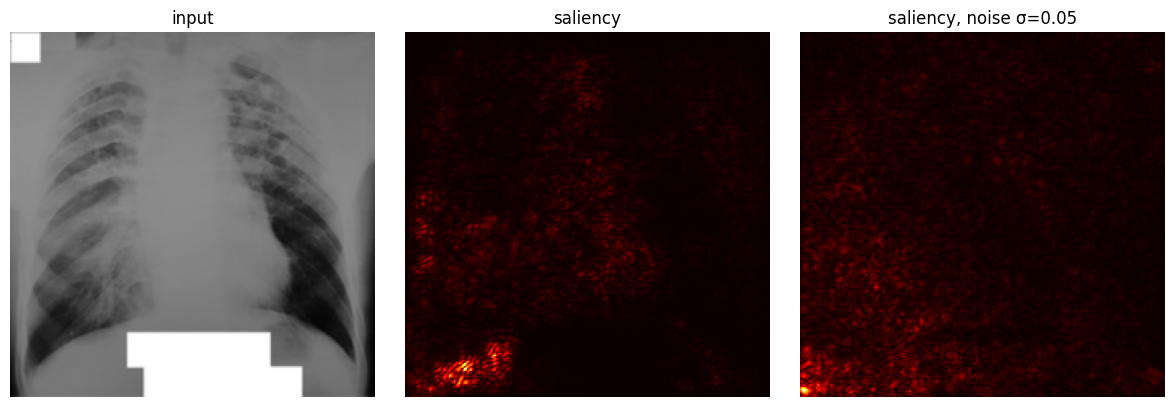

In [19]:
def saliency(model, x, target):
    model.eval()
    with torch.enable_grad():
        x = x.clone().requires_grad_(True)
        out = model(x); out[torch.arange(len(x), device=x.device), target].sum().backward()
    return x.grad.abs().amax(1).detach().cpu().numpy()

NOISE_SIGMA = 0.05                                       # in normalised-input units
g = torch.Generator().manual_seed(0)
sel = torch.randperm(len(TEST), generator=g)[:50].numpy()
rho, iou = [], []
for i in range(0, len(sel), 10):
    j = sel[i:i + 10]; x = to_input(TEST.X[j]); tgt = torch.tensor(pred[j], device=device)
    s0 = saliency(MAIN_MODEL, x, tgt)
    s1 = saliency(MAIN_MODEL, x + NOISE_SIGMA * torch.randn(x.shape, generator=g).to(device), tgt)
    for a, b in zip(s0, s1):
        rho.append(stats.spearmanr(a.ravel(), b.ravel())[0])
        ta, tb_ = a >= np.quantile(a, .9), b >= np.quantile(b, .9)
        iou.append((ta & tb_).sum() / (ta | tb_).sum())
SALIENCY_STATS = dict(n_images=len(rho), noise_sigma=NOISE_SIGMA, spearman_mean=float(np.mean(rho)),
                      spearman_sd=float(np.std(rho)), top10_iou_mean=float(np.mean(iou)), top10_iou_sd=float(np.std(iou)))
print(json.dumps(SALIENCY_STATS, indent=2))

x = to_input(TEST.X[sel[:1]]); tgt = torch.tensor(pred[sel[:1]], device=device)
a = saliency(MAIN_MODEL, x, tgt)[0]; b = saliency(MAIN_MODEL, x + NOISE_SIGMA * torch.randn_like(x), tgt)[0]
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
ax[0].imshow(TEST.X[sel[0]].numpy(), cmap="gray"); ax[0].set_title("input")
ax[1].imshow(a, cmap="hot"); ax[1].set_title("saliency"); ax[2].imshow(b, cmap="hot"); ax[2].set_title(f"saliency, noise σ={NOISE_SIGMA}")
for a_ in ax: a_.axis("off")
plt.tight_layout(); savefig("fig6b_saliency_stability.png"); plt.show()

## 19. LIME (with the same normalisation the model was trained with)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

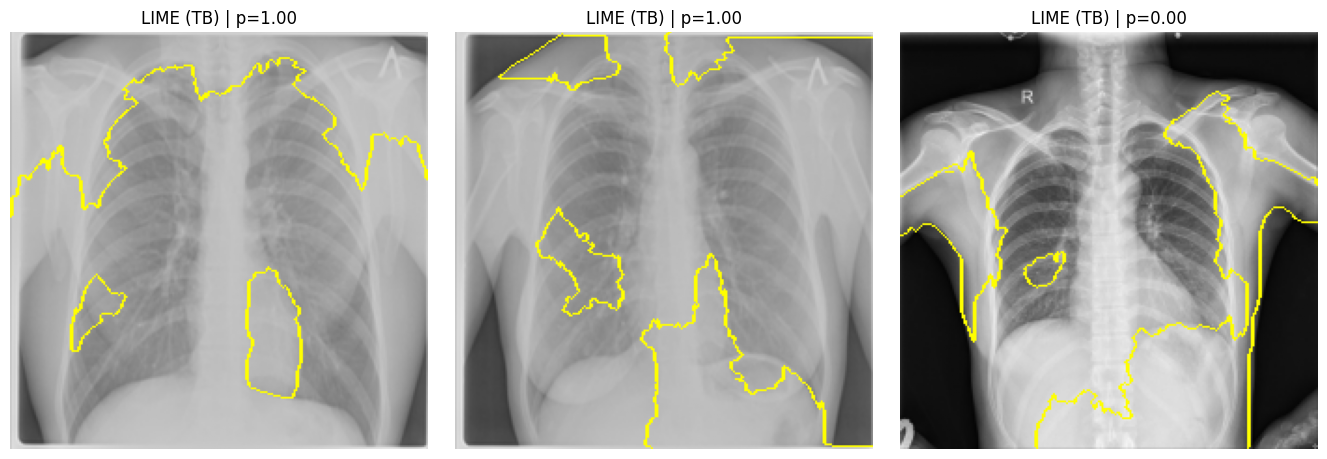

In [20]:
try:
    from lime import lime_image
    from skimage.segmentation import mark_boundaries
    @torch.no_grad()
    def lime_predict(batch):                               # [N,H,W,3] in [0,1]
        x = torch.tensor(batch, dtype=torch.float32, device=device).permute(0, 3, 1, 2)
        return torch.softmax(MAIN_MODEL((x - MEAN) / STD).float(), 1).cpu().numpy()
    explainer = lime_image.LimeImageExplainer(random_state=0)
    idxs = tp_idx[:2] + fn_idx[:1]
    fig, ax = plt.subplots(1, len(idxs), figsize=(4.5 * len(idxs), 4.5)); ax = np.atleast_1d(ax)
    for k, i in enumerate(idxs):
        rgb = np.repeat(TEST.X[i].numpy()[..., None], 3, 2).astype(np.float64) / 255
        exp = explainer.explain_instance(rgb, lime_predict, labels=(1,), top_labels=None, hide_color=0,
                                         num_samples=1000, batch_size=32, random_seed=0)
        temp, mask = exp.get_image_and_mask(1, positive_only=True, num_features=5, hide_rest=False)
        ax[k].imshow(mark_boundaries(temp, mask)); ax[k].set_title(f"LIME (TB) | p={p_main[i]:.2f}"); ax[k].axis("off")
    plt.tight_layout(); savefig("fig_lime.png"); plt.show()
except ImportError:
    print("lime not installed: run  !pip install lime  and re-run this cell (optional).")

## 20. SHAP (optional)

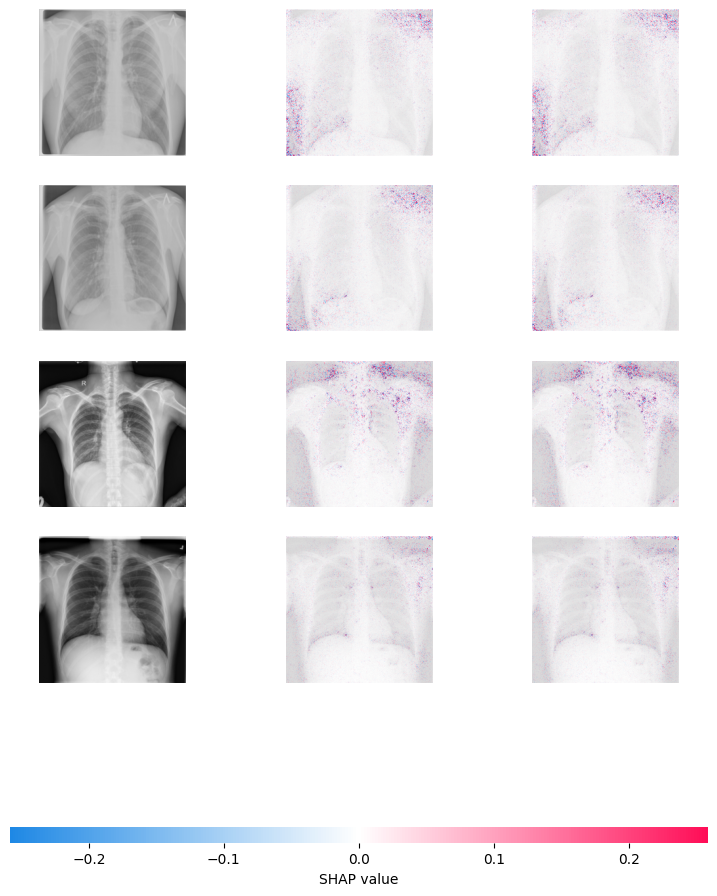

In [21]:
try:
    import shap
    bg_idx = np.random.default_rng(0).choice(len(POOLED), 50, replace=False)
    background = to_input(POOLED.X[bg_idx])
    ex_idx = np.array(tp_idx[:2] + fn_idx[:1] + [int(np.where(y_test == 0)[0][0])])
    explainer = shap.GradientExplainer(MAIN_MODEL, background, batch_size=10)
    sv = explainer.shap_values(to_input(TEST.X[ex_idx]), nsamples=50)
    sv = [sv[..., c] for c in range(sv.shape[-1])] if not isinstance(sv, list) else sv
    sv = [np.transpose(s, (0, 2, 3, 1)) for s in sv]
    imgs = np.repeat(TEST.X[ex_idx].numpy()[..., None], 3, 3) / 255
    shap.image_plot(sv, imgs, show=False); savefig("fig_shap.png"); plt.show()
except ImportError:
    print("shap not installed (optional).")
except Exception as e:
    print("SHAP failed (optional, does not affect other results):", e)

## 21. False-negative audit shows every missed TB case, up to 8

false negatives: 51 of 205 TB test images
Shenzhen    50
Tawsifur     1


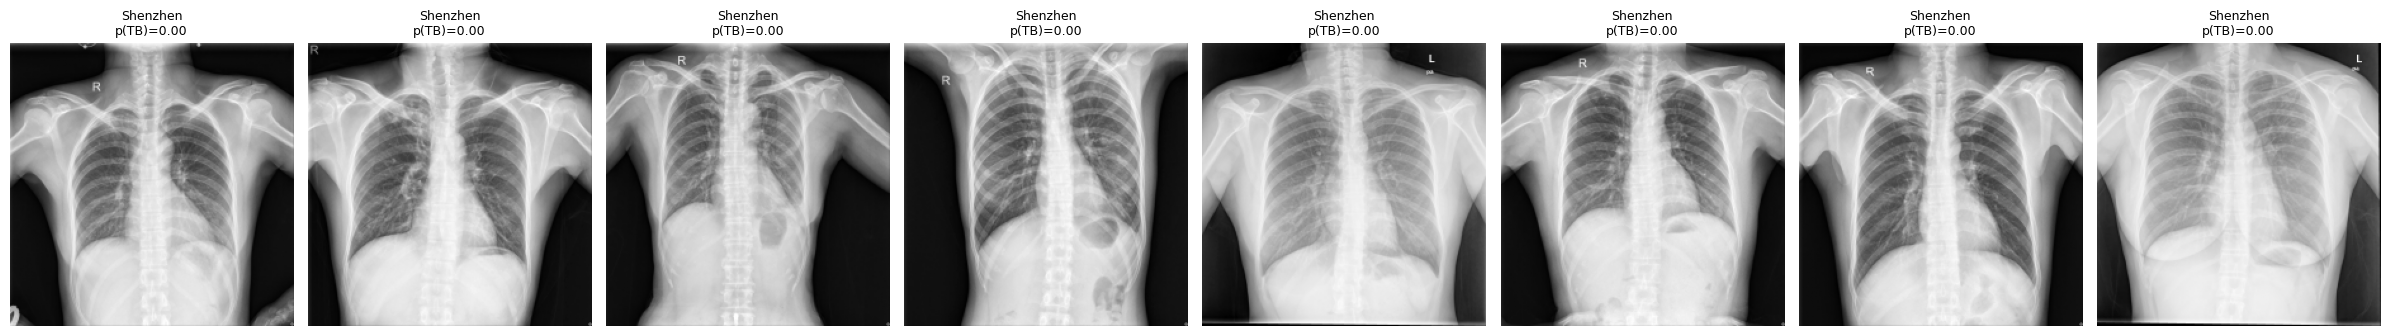

In [22]:
fn_all = [i for i in np.argsort(p_main) if y_test[i] == 1 and pred[i] == 0]
print(f"false negatives: {len(fn_all)} of {int((y_test == 1).sum())} TB test images")
print(pd.Series(TEST.source[fn_all]).value_counts().to_string() if fn_all else "none")
if fn_all:
    k = min(8, len(fn_all)); fig, ax = plt.subplots(1, k, figsize=(3 * k, 3.4)); ax = np.atleast_1d(ax)
    for a, i in zip(ax, fn_all[:k]):
        a.imshow(TEST.X[i].numpy(), cmap="gray"); a.set_title(f"{TEST.source[i]}\np(TB)={p_main[i]:.2f}", fontsize=9); a.axis("off")
    plt.tight_layout(); savefig("fig7_false_negatives.png"); plt.show()
pd.DataFrame(dict(path=TEST.path[fn_all], source=TEST.source[fn_all], p_tb=p_main[fn_all])).to_csv(
    os.path.join(OUT_DIR, "false_negatives.csv"), index=False)

## 22. Deployment efficiency (correct GPU timing)

In [23]:
def benchmark(model, dev, bs=1, iters=200, warmup=20):
    model = copy.deepcopy(model).to(dev).eval(); x = torch.randn(bs, 3, IMG, IMG, device=dev); t = []
    with torch.no_grad():
        for _ in range(warmup): model(x)
        if dev.type == "cuda": torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
        for _ in range(iters):
            if dev.type == "cuda": torch.cuda.synchronize()
            s = time.perf_counter(); model(x)
            if dev.type == "cuda": torch.cuda.synchronize()
            t.append((time.perf_counter() - s) * 1000)
    peak = torch.cuda.max_memory_allocated() / 2**20 if dev.type == "cuda" else np.nan
    return float(np.mean(t)), float(np.std(t)), peak

eff = []
for name, cls in ((PROPOSED, DenseNetAttention), (BASELINE, DenseNetBaseline)):
    m = cls(); m.load_state_dict(torch.load(run_file(name, MAIN_SEED, "pt"), map_location="cpu"))
    size_mb = sum(t.numel() * t.element_size() for t in list(m.parameters()) + list(m.buffers())) / 2**20
    row = dict(model=name, params=n_params(m), size_MB_fp32=round(size_mb, 2),
               checkpoint_MB=round(os.path.getsize(run_file(name, MAIN_SEED, "pt")) / 2**20, 2))
    if device.type == "cuda":
        mu, sd, peak = benchmark(m, device); mu32, _, _ = benchmark(m, device, bs=32, iters=50)
        row.update(gpu=ENV["gpu"], gpu_ms_bs1=round(mu, 2), gpu_ms_bs1_sd=round(sd, 2), gpu_fps_bs1=round(1000 / mu, 1),
                   gpu_imgs_per_s_bs32=round(32_000 / mu32, 1), gpu_peak_MB_bs1=round(peak, 1))
    mu, sd, _ = benchmark(m, torch.device("cpu"), iters=20, warmup=3)
    row.update(cpu_ms_bs1=round(mu, 1), cpu_threads=torch.get_num_threads())
    eff.append(row)
TABLE_EFF = pd.DataFrame(eff); print(TABLE_EFF.T.to_string())
TABLE_EFF.to_csv(os.path.join(OUT_DIR, "table_efficiency.csv"), index=False)

                                            0                              1
model                FL DenseNet121+Attention  FL DenseNet121 (no attention)
params                               11415170                        7216770
size_MB_fp32                            43.87                          27.85
checkpoint_MB                           44.14                          28.13
gpu                                  Tesla T4                       Tesla T4
gpu_ms_bs1                              14.58                          14.54
gpu_ms_bs1_sd                            0.66                           0.85
gpu_fps_bs1                              68.6                           68.8
gpu_imgs_per_s_bs32                     301.6                          319.9
gpu_peak_MB_bs1                         145.8                          129.8
cpu_ms_bs1                               85.1                           83.4
cpu_threads                                 2                              2

## 23. Everything of the research, in one file

In [24]:
PAPER = dict(
    environment=ENV,
    config=dict(CLIENT_C_SOURCE=CLIENT_C_SOURCE, CLIENT_C_SIZE=CLIENT_C_SIZE, BLUR_THRESHOLD=BLUR_THRESHOLD,
                BLUR_RES=BLUR_RES, NEAR_DUP_CORR=NEAR_DUP_CORR, SPLIT_ID=SPLIT_ID, SPLIT=SPLIT, DATA_SEED=DATA_SEED, SEEDS=SEEDS,
                NUM_ROUNDS=NUM_ROUNDS, LOCAL_EPOCHS=LOCAL_EPOCHS, BATCH_SIZE=BATCH_SIZE, LR=LR,
                WEIGHTED_FEDAVG=WEIGHTED_FEDAVG, USE_AMP=USE_AMP, model_selection="lowest validation loss"),
    cleaning=summary.reset_index().to_dict("records"), near_duplicates_removed=n_near,
    table1=TABLE1.to_dict("records"),
    table4_main=dict(seed=MAIN_SEED, confusion=dict(tp=m_main["tp"], fn=m_main["fn"], tn=m_main["tn"], fp=m_main["fp"]),
                     metrics={k: m_main[k] for k in KEYS}, ci95=ci_main,
                     best_round=RESULTS[(PROPOSED, MAIN_SEED)]["best_round"]),
    table5_ablation=TABLE_ABLATION.to_dict("records"),
    per_run={f"{n} | seed {s}": {k: RESULTS[(n, s)]["metrics"][k] for k in KEYS} for (n, s) in RESULTS},
    stats=TABLE_STATS.to_dict("records"), per_source=TABLE_SOURCE.to_dict("records"),
    source_probe=TABLE_PROBE.to_dict("records"), gradcam=GRADCAM_STATS, saliency=SALIENCY_STATS,
    efficiency=TABLE_EFF.to_dict("records"),
)
json.dump(PAPER, open(os.path.join(OUT_DIR, "paper_numbers.json"), "w"), indent=2, default=float)
print("Saved:", os.path.join(OUT_DIR, "paper_numbers.json"))
print("Figures:", sorted(os.listdir(FIG_DIR)))

Saved: /kaggle/working/tb_fl_outputs/paper_numbers.json
Figures: ['blur_distribution.png', 'fig3_confusion_roc_pr.png', 'fig4_convergence.png', 'fig4b_client_losses.png', 'fig5a_tsne.png', 'fig6a_gradcam.png', 'fig6b_saliency_stability.png', 'fig7_false_negatives.png', 'fig_calibration_dca.png', 'fig_lime.png', 'fig_shap.png', 'near_duplicate_pairs.png']


In [25]:
import os, shutil
from IPython.display import FileLink, display

src = "/kaggle/working/tb_fl_outputs"
assert os.path.isdir(src), "Output folder not found - run the notebook first."

zip_path = shutil.make_archive("/kaggle/working/tb_fl_outputs", "zip", root_dir=src)
print(f"Created {zip_path}  ({os.path.getsize(zip_path)/2**20:.1f} MB)")

os.chdir("/kaggle/working")          # FileLink needs a path relative to the working dir
display(FileLink("tb_fl_outputs.zip"))

Created /kaggle/working/tb_fl_outputs.zip  (330.4 MB)


/kaggle/working/tb_fl_outputs.zip

## 24. What outcome comes after this run

* **Table I / Sec. III-B** – copy `table1_data_distribution.csv`. With `CLIENT_C_SOURCE="tawsifur"` NIH is not used; with `"nih"` you must describe and cite NIH ChestX-ray14 (Wang et al., CVPR 2017).
* **Sec. III-C** – exact (MD5) duplicates removed, near duplicates between train and val/test removed by thumbnail correlation; blur filter not used (explain why with the blur histogram).
* **New subsection: data split** – 70/10/20 per source, stratified, fixed split seed; best round selected on validation loss; test set used once.
* **Eq. (2)** – if `WEIGHTED_FEDAVG=True`, write $W^{(t+1)}=\sum_i \frac{n_i}{n} W_i^{(t)}$ and cite McMahan et al. (2017).
* **Table IV** – `table4_main_model_ci.csv` (with 95% bootstrap CIs) and the confusion counts printed in Sec. 11.
* **Table V + statistics** – `table5_ablation_mean_sd.csv` and `table_stats_mcnemar_bootstrap.csv`; replace the Wilcoxon sentence with McNemar + paired bootstrap. Claim significance only if the results support it.
* **Fig. 4** – `fig4_convergence.png` (real log). Rewrite the convergence paragraph from the real curve.
* **Explainability / deployment** – use the numbers in `paper_numbers.json` (Grad-CAM energy, saliency correlation, latency). Delete the 91.6 % cost-reduction claim and any sentence the new outputs do not support.
* **Implementation** – versions from `environment.json`; mention mixed precision if `USE_AMP=True`.